# Gain selection with a third-order actuator

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/06-root-locus/notebook.ipynb)

## Goal
A normalized actuator has $G(s)=1/[s(s+2)(s+6)]$ under unity negative feedback with proportional gain $K>0$. Derive the strictly stable gain interval using Routh--Hurwitz, the imaginary-axis crossing and real-axis breakaway. Simulate $K=12$, $60$ and $100$ to compare regulation and instability. A short time plot alone is not a stability test.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/06-root-locus/figures/physical-system.png)

A motorized positioning axis illustrates the role of the integrator and two stable lags. The normalized transfer function is specified as a teaching model; the pictured dimensions do not identify its coefficients.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/06-root-locus/exercises.pdf) accompany this model.

## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/06-root-locus/figures/system-diagram.png)

Unity negative feedback and the open-loop pole map. Pole symbols provide the starting geometry for the root-locus exercises.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Characteristic equation
The unity-feedback denominator is

$$
p(s)=s(s+2)(s+6)+K=s^3+8s^2+12s+K.
$$

The first column of the Routh array is $1,8,(96-K)/8,K$. Strict stability therefore requires $0<K<96$. At $K=0$ there is a pole at the origin; $K=96$ is a boundary, not a stable maximum.
### Imaginary-axis crossing
At $K=96$, $p(s)=(s+8)(s^2+12)$, so the crossing pair is $s=\pm j\sqrt{12}$. The remaining pole stays at $-8$.
### Root-locus geometry
There are three open-loop poles and no finite zeros. The centroid is $-8/3$ and the asymptote angles are $60$, $180$ and $300$ degrees. Real-axis locus segments are $(-\infty,-6)$ and $(-2,0)$.
Since $K(s)=-s(s+2)(s+6)$, a stationary point satisfies $3s^2+16s+12=0$. The root $(-8+2\sqrt7)/3\simeq-0.9028$ belongs to $(-2,0)$ and is the valid positive-gain breakaway. The other stationary point does not lie on a positive-gain real-axis segment.
### Checking the plots
Use pole real parts to classify each gain before plotting. A finite horizon can conceal instability when an unstable real part is small. For stable positive gains, the integrator in the open loop gives zero constant-reference error, but says nothing about overshoot.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
plant=ct.tf([1],[1,8,12,0])
time=np.linspace(0,20,6001)
responses=[]
for gain in [12.,60.,100.]:
    closed=ct.feedback(gain*plant,1)
    poles=ct.poles(closed)
    assert (np.max(poles.real)<0)==(gain<96)
    _,output=ct.step_response(closed,time)
    responses.append((gain,output))
    print(f'K={gain:.0f}: largest pole real part={poles.real.max():.6f}')
breakaway=(-8+2*np.sqrt(7))/3
break_gain=-breakaway*(breakaway+2)*(breakaway+6)
print(f'Breakaway={breakaway:.8f}; gain={break_gain:.8f}; boundary frequency={np.sqrt(12):.8f} rad/s')
gains=np.linspace(0,130,600)
all_poles=np.array([np.roots([1,8,12,g]) for g in gains])


K=12: largest pole real part=-0.788757


K=60: largest pole real part=-0.265547


K=100: largest pole real part=0.026030
Breakaway=-0.90283246; gain=5.04904248; boundary frequency=3.46410162 rad/s


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

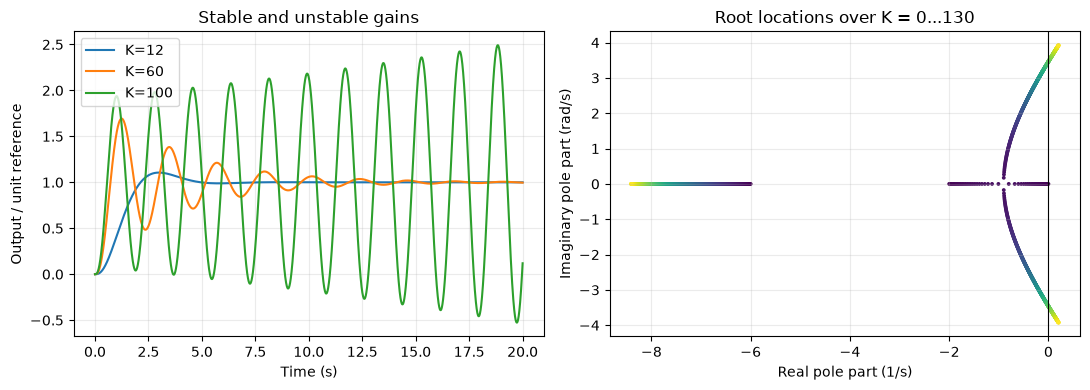

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for gain,output in responses: axes[0].plot(time,output,label=f'K={gain:g}')
axes[0].set(xlabel='Time (s)',ylabel='Output / unit reference',title='Stable and unstable gains'); axes[0].legend()
axes[1].scatter(all_poles.real,all_poles.imag,s=3,c=np.repeat(gains,3),cmap='viridis')
axes[1].axvline(0,color='black',lw=.8); axes[1].set(xlabel='Real pole part (1/s)',ylabel='Imaginary pole part (rad/s)',title='Root locations over K = 0...130')
fig.tight_layout()

plt.show()

## Interpret and extend
An algebraic stability interval provides a guardrail for numerical tuning. The endpoint K=96 must be excluded from strict asymptotic stability.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)